# Getting started: the three processor models

This notebook shows how to load the common processor definitions of the Basic track,
look at the three coupling graphs, and compile a Bell-state circuit onto the two ports.
Measuring XX, YY and ZZ, estimating the fidelity and adding a protection strategy
(Tasks 3-7) are left to your team.

Keep this notebook in the same folder as `qff_basic_benchmark.py`. Install the packages once,
from a terminal opened in that folder: `pip install -r requirements.txt`

In [1]:
import qiskit, qiskit_aer, qiskit_ibm_runtime
from qiskit import QuantumCircuit, transpile

from qff_basic_benchmark import MODEL_NAMES, SHOTS, load_model, draw_model

# The contemporary model is defined by the FakeFez snapshot in qiskit-ibm-runtime 0.50.0.
print("qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__,
      "| qiskit-ibm-runtime", qiskit_ibm_runtime.__version__)
print("shots per circuit:", SHOTS)

qiskit 2.5.2 | qiskit-aer 0.17.2 | qiskit-ibm-runtime 0.50.0
shots per circuit: 10000


## 1. Load the models

`load_model(name)` returns a `ProcessorModel` with the coupling graph, the two ports,
the native gates, and two simulators that share one compilation target:

* `model.backend`: noisy simulator (use for the noisy and protected cases)
* `model.ideal_backend`: same target, no noise (use for the ideal baseline)

Loading the contemporary model takes a few seconds because it builds the FakeFez noise model.

In [2]:
models = {name: load_model(name) for name in MODEL_NAMES}

for name, m in models.items():
    noise = m.error_rates if m.error_rates is not None else f"{m.noise_source} calibration data (Aer)"
    print(f"{name:13s} qubits={m.num_qubits:3d}  couplers={len(m.edges):3d}  "
          f"ports={m.ports}  port distance={m.port_distance()}  gates={m.basis_gates}")
    print(f"{'':13s} noise: {noise}")

2016          qubits=  5  couplers=  4  ports=(0, 4)  port distance=3  gates=('cx', 'u1', 'u2', 'u3')
              noise: FakeBurlingtonV2 calibration data (Aer)
contemporary  qubits=156  couplers=176  ports=(126, 129)  port distance=3  gates=('cz', 'rz', 'sx', 'x')
              noise: FakeFez calibration data (Aer)
hyperbolic    qubits= 35  couplers= 42  ports=(0, 3)  port distance=3  gates=('cz', 'rz', 'sx', 'x')
              noise: {'one_qubit': 0.000229, 'two_qubit': 0.0039, 'readout': 0.00757}


## 2. Draw the coupling graphs

Port A is green and port B is purple. The hyperbolic graph is drawn at its positions in the
Poincare disk (dashed circle = disk boundary): every face is a heptagon and three faces meet
at each interior vertex.

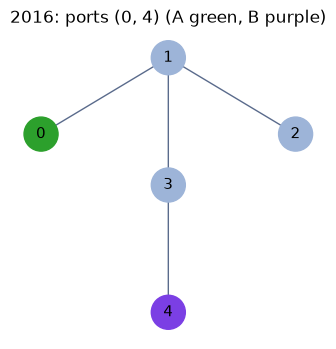

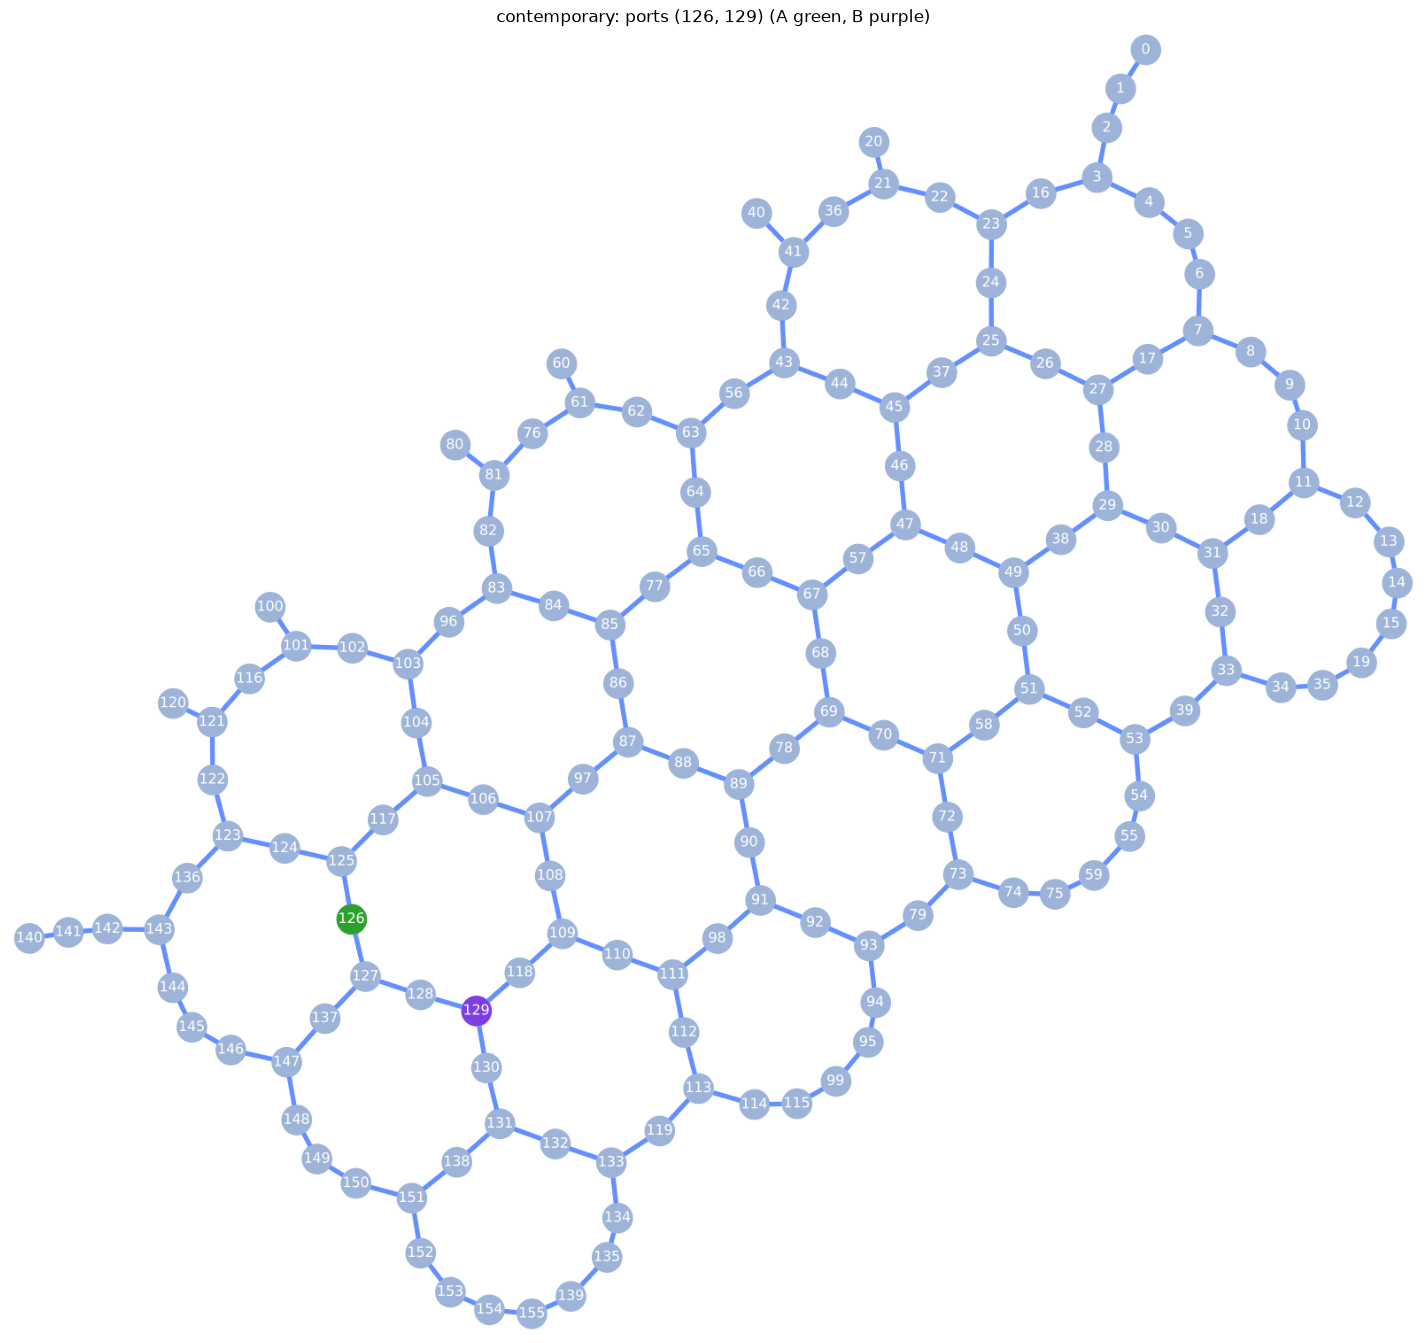

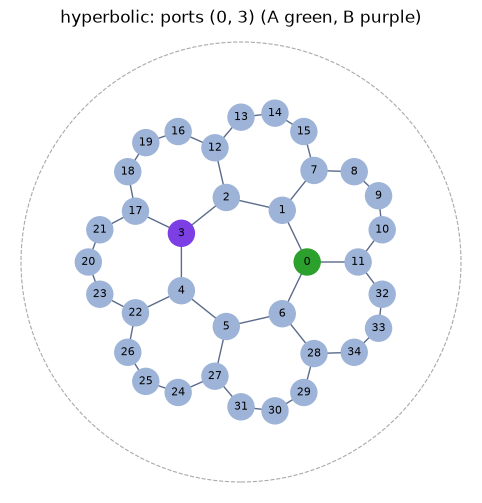

In [3]:
import matplotlib.pyplot as plt
from IPython.display import display

for name in MODEL_NAMES:
    fig = draw_model(models[name])
    display(fig)      # show each figure once
    plt.close(fig)

## 3. Compile the Bell circuit onto the ports

Build the 2-qubit circuit with its measurements **before** compiling, so only the two ports
are measured. `initial_layout=list(m.ports)` places logical qubit 0 on port A and logical
qubit 1 on port B. Always compile against the model's target (`transpile(..., m.backend)` or
`generate_preset_pass_manager(target=m.target, ...)`): the simulator itself does not reject
a gate between qubits that are not coupled, so an uncompiled circuit would run but would not
be a valid result.

In [4]:
bell = QuantumCircuit(2, 2)
bell.h(0)
bell.cx(0, 1)
bell.measure([0, 1], [0, 1])

compiled = {}
for name, m in models.items():
    tq = transpile(bell, m.backend, initial_layout=list(m.ports), seed_transpiler=2026)
    compiled[name] = tq
    two_q = sum(1 for inst in tq.data if inst.operation.num_qubits == 2)
    print(f"{name:13s} depth={tq.depth():3d}  two-qubit gates={two_q}  ops={dict(tq.count_ops())}")

2016          depth=  6  two-qubit gates=7  ops={'cx': 7, 'measure': 2, 'u2': 1}
contemporary  depth= 13  two-qubit gates=7  ops={'sx': 13, 'rz': 11, 'cz': 7, 'measure': 2}
hyperbolic    depth= 13  two-qubit gates=7  ops={'sx': 14, 'cz': 7, 'rz': 5, 'measure': 2}


The ports are 3 couplers apart on every model, so routing needs two SWAPs (3 two-qubit gates
each) plus the CNOT: 7 two-qubit gates. Here is the compiled circuit on the 2016 model
(FakeBurlington's older u1/u2/u3 + cx gate set), restricted to the qubits it uses:

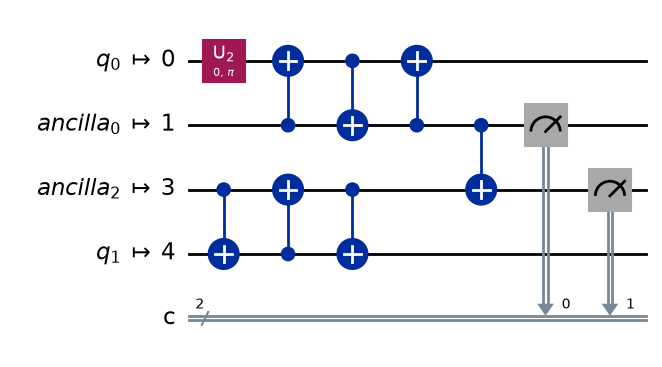

In [5]:
compiled["2016"].draw("mpl", idle_wires=False, fold=-1)

## 4. Bit order

Qiskit prints counts with classical bit 0 on the **right**. With the circuit above, clbit 0
holds port A and clbit 1 holds port B, so the key `"01"` means port A = 1, port B = 0. Check:

In [6]:
check = QuantumCircuit(2, 2)
check.x(0)                     # flip port A only
check.measure([0, 1], [0, 1])
m = models["hyperbolic"]
tq = transpile(check, m.backend, initial_layout=list(m.ports), seed_transpiler=2026)
print(m.ideal_backend.run(tq, shots=100).result().get_counts())   # expect {'01': 100}

{'01': 100}


## 5. One noisy run in the Z basis

The Z basis alone cannot verify a Bell pair: a classical mixture of 00 and 11 gives the same
correlations. Use it here only to see that the simulators run. Verification with XX, YY and ZZ
is Task 3.

In [7]:
for name, m in models.items():
    counts = m.backend.run(compiled[name], shots=SHOTS, seed_simulator=2026).result().get_counts()
    same = (counts.get("00", 0) + counts.get("11", 0)) / SHOTS
    print(f"{name:13s} P(outcomes agree) = {same:.4f}   {dict(sorted(counts.items()))}")

2016          P(outcomes agree) = 0.8999   {'00': 4564, '01': 498, '10': 503, '11': 4435}


contemporary  P(outcomes agree) = 0.9654   {'00': 4805, '01': 176, '10': 170, '11': 4849}
hyperbolic    P(outcomes agree) = 0.9725   {'00': 4837, '01': 141, '10': 134, '11': 4888}


## 6. The "common" noise variant (for Task 6)

`load_model(name, noise="common")` keeps each graph and its ports but gives all three models the
same gate set (`cz, rz, sx, x`) and the same noise (FakeFez median error rates). Differences that
remain between the models then come from the coupling graph alone.

In [8]:
common = {name: load_model(name, noise="common") for name in MODEL_NAMES}
for name, m in common.items():
    print(f"{name:13s} gates={m.basis_gates}  noise={m.error_rates}")

2016          gates=('cz', 'rz', 'sx', 'x')  noise={'one_qubit': 0.000229, 'two_qubit': 0.0039, 'readout': 0.00757}
contemporary  gates=('cz', 'rz', 'sx', 'x')  noise={'one_qubit': 0.000229, 'two_qubit': 0.0039, 'readout': 0.00757}
hyperbolic    gates=('cz', 'rz', 'sx', 'x')  noise={'one_qubit': 0.000229, 'two_qubit': 0.0039, 'readout': 0.00757}
